# Model Development Anomaly Detection

This notebook trains the anomaly detection models using the benign frequency features created in the previous notebook (`feature_engineering`). The whole approach is benign-only, which means the models learn what normal Java execution looks like and then flag anything that deviates from it. 
Two models are used here are `IsolationForest` and `OneClassSVM`, and both are evaluated on how well they recognise unseen benign files as normal.

Because of the ethics constraint, no malware is used at any point. The models are trained and validated on benign data alone, and synthetic anomaly traces will be added in a later step to test the separation of benign and anomalous traces. The trained models will be saved for later use in joblib format.


## Setup the imports and paths

In [1]:
import os
import time
import json
import numpy as np
import pandas as pd
import joblib

from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.svm import OneClassSVM
from sklearn.model_selection import KFold

In [2]:
# Feature files from the previous notebook (feature_engineering)
FEATURES_DIR = "../sandbox/data-e2/features"
FREQ_CSV = os.path.join(FEATURES_DIR, "frequency_features.csv")
ENTROPY_CSV = os.path.join(FEATURES_DIR, "opcode_entropy.csv")

# Where trained models get saved so synthetic anomalies can be scored later
MODELS_DIR = "../sandbox/data-e2/models"
os.makedirs(MODELS_DIR, exist_ok=True)

# Fixed seed for reproduce, because for a small dataset - reproducibility matters
RANDOM_STATE = 42

## Loading the Frequency Features

The frequency feature matrix has one row per file and one column per opcode, with the values already normalised into proportions (weight) in the previous notebook. The `sample_id` column holds the file names and is kept separate from the numeric matrix `X`. The row-sum check confirms each file opcode proportions add up to about 1.0, which is a quick way to confirm the features loaded correctly and nothing was corrupted along the way.


In [3]:
# Load the 260 x 287 frequency matrix. Column 0 is sample_id and rest are opcode proportions
df_freq = pd.read_csv(FREQ_CSV)

df_freq.head()

,sample_id,ADC,ADD,ADDSD,ADDSS,ADD_LOCK,AND,ANDN,ANDNPS,ANDPD,...,XADD_LOCK,XCHG,XCHG_LOCK,XGETBV,XOR,XORPD,XORPS,XOR_LOCK,XRSTOR,XSAVEC
0,GommeHD.net-Java-API-2.2.0-jar-with-dependencies,0.000318,0.054942,0.000072,0.000001,0.000162,0.018977,3.809468e-08,2.285681e-08,0.000009,...,0.000089,0.000251,7.237990e-08,1.142841e-08,0.010101,0.0,7.618937e-09,0.0,3.428522e-08,3.428522e-08
1,abbot-0.13.0,0.000158,0.055361,0.000034,0.000006,0.000157,0.018124,3.999747e-08,2.399848e-08,0.000004,...,0.000076,0.000229,7.199545e-08,1.199924e-08,0.009882,0.0,3.999747e-09,0.0,3.599773e-08,3.599773e-08
2,activecluster-4.0.2,0.000492,0.056953,0.000025,0.000001,0.000223,0.017952,6.763775e-08,3.642033e-08,0.000004,...,0.000108,0.000322,7.804356e-08,1.560871e-08,0.010516,0.0,0.000000e+00,0.0,4.682614e-08,4.682614e-08
3,activemq-4.0-M1,0.000189,0.055250,0.000034,0.000001,0.000217,0.019440,1.973805e-08,2.368566e-08,0.000004,...,0.000094,0.000282,4.737132e-08,1.184283e-08,0.010170,0.0,0.000000e+00,0.0,3.552849e-08,3.552849e-08
4,activemq-all-6.2.6,0.000158,0.056274,0.000082,0.000001,0.000139,0.020579,2.813875e-08,2.411893e-08,0.000011,...,0.000082,0.000240,5.225768e-08,1.205947e-08,0.009610,0.0,0.000000e+00,0.0,3.617840e-08,3.617840e-08


In [4]:
sample_ids = df_freq["sample_id"].tolist()
opcode_cols = [c for c in df_freq.columns if c != "sample_id"]

# X is the benign feature matrix which has one row per file and one column per opcode (already normalized)
X = df_freq[opcode_cols].to_numpy(dtype=np.float64)

print(f"Loaded Frequency Features: {X.shape[0]} files x {X.shape[1]} opcodes")
print(f"Sample IDs: {len(sample_ids)} (First: {sample_ids[0]})")

# Check the range of values in the feature matrix and confirm row sums are around 1.0
print(f"Value Range: min = {X.min():.6f}, max = {X.max():.6f}")
print(f"Row Sums (should be around 1.0): min = {X.sum(axis=1).min():.4f}, max = {X.sum(axis=1).max():.4f}")


Loaded Frequency Features: 260 files x 287 opcodes
Sample IDs: 260 (First: GommeHD.net-Java-API-2.2.0-jar-with-dependencies)
Value Range: min = 0.000000, max = 0.333561
Row Sums (should be around 1.0): min = 1.0000, max = 1.0000


## Standardizing the Features

The One-Class SVM uses an RBF kernel (Radial Basis Function), which measures distances between points so features on very different scales can distort the learned boundary. Standardizing each opcode column to zero mean and unit variance fixes this. 
The Isolation Forest is tree-based and is not affected by scaling, but the same standardized data is used for both models so the comparison between them stays fair and consistent.

One important detail is that the scaler must only be fitted on training data, never on the test files. The preview below is fitted on all data just to confirm the scaling behaves as expected. In the actual hold-out split and the k-fold cross-validation, the scaler is re-fitted on the training rows only, so no information about the test files leaks into the model so that the evaluation is fair and unbiased.



In [5]:
# This is only a preview to see the effect of scaling
scaler = StandardScaler()
X_scaled_preview = scaler.fit_transform(X)

print(f"Before Scaling: mean = {X.mean():.6f}, std = {X.std():.6f}")
print(f"After Scaling: mean = {X_scaled_preview.mean():.6f}, std = {X_scaled_preview.std():.6f}")

Before Scaling: mean = 0.003484, std = 0.020280
After Scaling: mean = -0.000000, std = 0.984196


## Hold Out Split Check

Before the main k-fold evaluation a single hold-out split is used as a quick sanity check. The benign files are split into a training set of about 80% and a held-out test set of about 20%. The models are trained on the training set and then asked to make predictions on the held-out files, which they have never seen. 
Because every one of these files is benign the ideal result is that almost all of them are recognised as normal traces. Any benign file that gets flagged is a false positive, and the false positive rate is the key number for a benign-only detector.

This split is mainly for seeing and debugging. It lets the actual anomaly scores be checked directly before trusting any averaged result. The scaler is fitted on the training rows only, then used to transform both the training and the test rows so no information about the held-out files leaks into the model while training.


In [6]:
from sklearn.model_selection import train_test_split

# 80/20 split of the benign files
idx_train, idx_test = train_test_split(
    np.arange(X.shape[0]), 
    test_size = 0.20, 
    random_state = RANDOM_STATE
)

X_train_raw, X_test_raw = X[idx_train], X[idx_test]

print(f"Training Files: {X_train_raw.shape[0]}")
print(f"Held-out Test Files: {X_test_raw.shape[0]}")

Training Files: 208
Held-out Test Files: 52


In [7]:
# Fit the scaler on training rows only then transform both train and test with those numbers
holdout_scaler = StandardScaler()
X_train = holdout_scaler.fit_transform(X_train_raw) # fit + transform on train
X_test = holdout_scaler.transform(X_test_raw) # transform test with train mean/std

## Training and Scoring on the Hold Out Split

Two models are trained here. 
- The `IsolationForest` isolates anomalies by randomly splitting the feature space. Since points that are different are easier to separate and need fewer splits. 
- The `OneClassSVM` learns a boundary that encloses most of the benign training data and treats anything outside it as an anomaly. 

Both are told to expect only a small fraction of outliers because the training data is entirely benign. Each model labels a file as either normal or anomalous. Since the heldout files are all benign the false positive rate is simply the weight of them that were wrongly flagged as anomalies. A low false positive value here means the model has learned the benign baseline well.


In [8]:
# contamination and nu = expected outlier fraction in training which is set to Low since training is benign-only
CONTAMINATION = 0.05  # Isolation Forest
NU = 0.05  # One-Class SVM

def false_positive_rate(predictions):
    # sklearn convention: +1 = normal (inlier) and -1 = anomaly (outlier)
    # All test files are benign so every -1 is a false positive here
    return np.mean(predictions == -1)

### Isolation Forest

In [9]:
iso = IsolationForest(
    contamination = CONTAMINATION,
    random_state = RANDOM_STATE,
    n_estimators = 200
)

iso.fit(X_train)
iso_pred_test = iso.predict(X_test)
iso_fpr = false_positive_rate(iso_pred_test)

### One-Class SVM

In [10]:
ocsvm = OneClassSVM(
    kernel = "rbf",
    nu = NU,
    gamma = "scale"
)

ocsvm.fit(X_train)
ocsvm_pred_test = ocsvm.predict(X_test)
ocsvm_fpr = false_positive_rate(ocsvm_pred_test)

In [11]:
print("Hold Out Results (false positive rate on unseen benign files):")
print(f" Isolation Forest: {iso_fpr:.3f} ({int(iso_fpr * len(X_test))} of {len(X_test)} flagged)")
print(f" One-Class SVM: {ocsvm_fpr:.3f} ({int(ocsvm_fpr * len(X_test))} of {len(X_test)} flagged)")

Hold Out Results (false positive rate on unseen benign files):
 Isolation Forest: 0.077 (4 of 52 flagged)
 One-Class SVM: 0.192 (10 of 52 flagged)


## K-Fold Cross-Validation - Training and Scoring (Main Focus)

The hold-out split gives just one result which depends heavily on which files happened to land in the test set. With only 260 files this single number cannot be fully trusted. But K-fold cross-validation solves this by splitting the data into k equal folds, training on k-1 folds and testing on the remaining one, then rotating so that every file is used as a test file exactly once. This is the main reason k-fold is used here because the dataset is small so every file can contributes to the model evaluation.

The false positive rate (FRP) is recorded for each fold and the mean and standard deviation across all folds are reported. The mean value gives the overall expected false positive rate and the standard deviation shows how stable the model is across different splits. 

Same as before, the scaler is fitted on each fold training rows only and then used to transform both the training and the test rows of that fold.


In [12]:
K = 5
kf = KFold(
    n_splits = K, 
    shuffle = True, 
    random_state = RANDOM_STATE
)

iso_fold_fprs = [] # List to store false positive rates for Isolation Forest across folds
ocsvm_fold_fprs = [] # List to store false positive rates for One-Class SVM across folds

for fold, (tr_idx, te_idx) in enumerate(kf.split(X), start=1):
    
    # Fit scaler on this fold's training rows only, transform both train and test.
    fold_scaler = StandardScaler()
    X_tr = fold_scaler.fit_transform(X[tr_idx]) # fit + transform on train
    X_te = fold_scaler.transform(X[te_idx]) # transform test with train mean/std

    # Isolation Forest
    iso_f = IsolationForest(contamination=CONTAMINATION, random_state=RANDOM_STATE, n_estimators=200)
    iso_f.fit(X_tr)
    iso_fold_fprs.append(false_positive_rate(iso_f.predict(X_te)))

    # One-Class SVM
    ocsvm_f = OneClassSVM(kernel="rbf", nu=NU, gamma="scale")
    ocsvm_f.fit(X_tr)
    ocsvm_fold_fprs.append(false_positive_rate(ocsvm_f.predict(X_te)))

    print(f"Fold {fold}: IsoForest FPR = {iso_fold_fprs[-1]:.3f} | "
            f"OC-SVM FPR = {ocsvm_fold_fprs[-1]:.3f}")

Fold 1: IsoForest FPR = 0.077 | OC-SVM FPR = 0.192
Fold 2: IsoForest FPR = 0.058 | OC-SVM FPR = 0.288
Fold 3: IsoForest FPR = 0.038 | OC-SVM FPR = 0.135
Fold 4: IsoForest FPR = 0.000 | OC-SVM FPR = 0.250
Fold 5: IsoForest FPR = 0.115 | OC-SVM FPR = 0.327


In [13]:
iso_fold_fprs = np.array(iso_fold_fprs)
ocsvm_fold_fprs = np.array(ocsvm_fold_fprs)

print("\nK-fold False Positive Rate (mean & std across folds):")

print(f"\n Isolation Forest")
print(f"  Mean: {iso_fold_fprs.mean():.3f} | Std: {iso_fold_fprs.std():.3f}")

print(f"\n One-Class SVM")
print(f"  Mean: {ocsvm_fold_fprs.mean():.3f} | Std: {ocsvm_fold_fprs.std():.3f}")


K-fold False Positive Rate (mean & std across folds):

 Isolation Forest
  Mean: 0.058 | Std: 0.038

 One-Class SVM
  Mean: 0.238 | Std: 0.068


## One-Class SVM - Hyperparameter Tuning

The One-Class SVM flagged far more benign files than the Isolation Forest, so before saving the models it is worth checking whether this is due to the parameter settings or genuine weakness of the model for this data. 

The `nu` parameter controls how many training points are allowed to fall outside the boundary, and `gamma` controls how tightly the RBF kernel wraps around the data. A small grid of values is tested with the same k-fold false positive measurement, so the effect of each setting can be seen directly.


In [14]:
from itertools import product

# Grid search for One-Class SVM hyperparameters
nu_values    = [0.01, 0.02, 0.05, 0.10]
gamma_values = ["scale", "auto", 0.01, 0.1]

print(f"{'nu':>6} {'gamma':>8} {'mean_FPR':>10} {'std':>8}")
print("-" * 36)

# Perform grid search
for nu_v, gamma_v in product(nu_values, gamma_values):
    
    fold_fprs = []
    
    for tr_idx, te_idx in kf.split(X):
        
        s = StandardScaler()
        X_tr = s.fit_transform(X[tr_idx])
        X_te = s.transform(X[te_idx])
        
        hymodel = OneClassSVM(kernel="rbf", nu=nu_v, gamma=gamma_v)
        hymodel.fit(X_tr)
        fold_fprs.append(false_positive_rate(hymodel.predict(X_te)))
        
    fold_fprs = np.array(fold_fprs)
    
    print(f"{nu_v:>6} {str(gamma_v):>8} {fold_fprs.mean():>10.3f} {fold_fprs.std():>8.3f}")
    

    nu    gamma   mean_FPR      std
------------------------------------
  0.01    scale      0.238    0.068
  0.01     auto      0.238    0.068
  0.01     0.01      0.585    0.079
  0.01      0.1      1.000    0.000
  0.02    scale      0.238    0.068
  0.02     auto      0.238    0.068
  0.02     0.01      0.585    0.079
  0.02      0.1      1.000    0.000
  0.05    scale      0.238    0.068
  0.05     auto      0.238    0.068
  0.05     0.01      0.585    0.079
  0.05      0.1      1.000    0.000
   0.1    scale      0.242    0.074
   0.1     auto      0.238    0.068
   0.1     0.01      0.585    0.079
   0.1      0.1      1.000    0.000


### Discussion of Above Tuning Results

The tuning grid shows a clear pattern. Changing `nu` from 0.01 up to 0.10 couldn't even move the false positive rate at all. Which stays around 0.246 for the `scale` setting. The `gamma` parameter, on the other hand dominates completely. At `gamma = 0.01` the false positive rate rises to 0.600, and at `gamma = 0.1` every single benign file is flagged as an anomaly.

This means the problem is not the choice of `nu`. The RBF kernel is too aggressive in this 287 dimensional feature space. As a result, the boundary tightly fits around each individual training file instead of creating one clear area around the benign data. Any unseen benign file then falls outside that boundary and gets flagged. This is a known effect of high dimensional data, where distances between points become less meaningful and distance based methods start to break down, and give false results.

This is a useful result rather than a failure model. It shows that the One-Class SVM is not competitive on raw 287 dimensional frequency features, and it gives a measured, evidence why it's failing.


----
## Adding Two More Anomaly Detection Models

So far only two models have been tested. But to make the comparison more complete another two models are added, both of which come from different types of anomaly detection. This means the comparison covers several different ways of deciding what counts as normal rather than testing small variations of the same approach.

- The `LocalOutlierFactor` is a density-based method. It looks for unusual files based on their surrounding files. It checks each file against its closest neighbors and flags a file as an outlier if it is in a much less crowded area than those around it. When set to `novelty=True`, it can learn from benign data and then be used to evaluate new, unseen files, similar to other models.

- The `EllipticEnvelope` works differently than the others. It assumes that the benign data roughly forms a single Gaussian shape and fits a robust ellipse around it and anything that falls outside this ellipse is flagged as unusual. This method has a specific assumption about the shape of the data, unlike the other three methods, which do not assume anything about the shape of the data. It may be struggle with 287 features and only 260 files.

In [15]:
from sklearn.neighbors import LocalOutlierFactor
from sklearn.covariance import EllipticEnvelope

# All four models are built fresh inside each fold. Keeping them in a function
# Means every model sees exactly the same folds and the same scaling so the comparison is fair
def build_models():
    return {
        "Isolation Forest": IsolationForest(
            contamination = CONTAMINATION, 
            random_state = RANDOM_STATE, 
            n_estimators = 200
        ),
        "One-Class SVM": OneClassSVM(
            kernel = "rbf", 
            nu = NU, 
            gamma = "scale"
        ),
        "Local Outlier Factor": LocalOutlierFactor(
            n_neighbors = 20, 
            contamination = CONTAMINATION, 
            novelty = True
        ),
        "Elliptic Envelope": EllipticEnvelope(
            contamination = CONTAMINATION, 
            random_state = RANDOM_STATE, 
            support_fraction = 0.9
        ),
    }

print("Models To Evaluate:")
for i, name in enumerate(build_models(), start=1):
    print(f" {i}. {name}")

Models To Evaluate:
 1. Isolation Forest
 2. One-Class SVM
 3. Local Outlier Factor
 4. Elliptic Envelope


## K-Fold Evaluation of All Four Models

All four models are now evaluated together using the same k-fold split so the results are directly can be compared. In each fold the scaler is fitted on the training rows only and then used to transform both the training and the test rows, which keeps the evaluation free of data leakage. Every model is trained on the same benign training files and then asked to make predictions on the same held-out benign files.

Because every test file is benign, any file flagged as an anomaly is a false positive. The false positive rate is recorded for each fold, and the mean and standard deviation across the folds are displayed. The mean shows the expected false positive rate, while the standard deviation shows how stable each model is across different splits of the small dataset.

In [16]:
import warnings
warnings.filterwarnings("ignore")

fold_results = {name: [] for name in build_models()}

for fold, (tr_idx, te_idx) in enumerate(kf.split(X), start=1):
    
    # Fit scaler on this fold's training rows only, transform both train and test.
    fold_scaler = StandardScaler()
    X_tr = fold_scaler.fit_transform(X[tr_idx]) # fit + transform on train
    X_te = fold_scaler.transform(X[te_idx]) # transform test with train mean/std

    row = []
    
    for name, model in build_models().items():
        model.fit(X_tr)
        fpr = false_positive_rate(model.predict(X_te))
        fold_results[name].append(fpr)
        row.append(f"{name} = {fpr:.3f}")

    print(f"Fold {fold}: " + " | ".join(row))

Fold 1: Isolation Forest = 0.077 | One-Class SVM = 0.192 | Local Outlier Factor = 0.058 | Elliptic Envelope = 0.365
Fold 2: Isolation Forest = 0.058 | One-Class SVM = 0.288 | Local Outlier Factor = 0.096 | Elliptic Envelope = 0.538
Fold 3: Isolation Forest = 0.038 | One-Class SVM = 0.135 | Local Outlier Factor = 0.019 | Elliptic Envelope = 0.615
Fold 4: Isolation Forest = 0.000 | One-Class SVM = 0.250 | Local Outlier Factor = 0.019 | Elliptic Envelope = 0.750
Fold 5: Isolation Forest = 0.115 | One-Class SVM = 0.327 | Local Outlier Factor = 0.077 | Elliptic Envelope = 0.654


### Summary Comparison of All Models

The table below displays the results together. The mean false positive rate is the main number, because it shows how often a benign file would be wrongly flagged in normal use. The standard deviation matters just as much on a dataset this small, because it shows whether the result holds up across different splits or was simply it's a lucky split. A model that is unstable across different splits is not reliable and cannot be trusted to work well in practice.


In [17]:
summary = pd.DataFrame([
    {
        "Model": name,
        "Mean FPR": np.mean(fprs),
        "Std": np.std(fprs),
        "Min FPR": np.min(fprs),
        "Max FPR": np.max(fprs),
    }
    for name, fprs in fold_results.items()
]).sort_values("Mean FPR").reset_index(drop=True)

print("K-Fold False Positive Rate on unseen benign files (low value is better)\n")
print(summary.to_string(index=False, float_format=lambda v: f"{v:.3f}"))

summary.to_csv(os.path.join(MODELS_DIR, "model_comparison_approach_1.csv"), index=False)
print(f"\nSaved Comparison table to {MODELS_DIR}/model_comparison_approach_1.csv")

K-Fold False Positive Rate on unseen benign files (low value is better)

               Model  Mean FPR   Std  Min FPR  Max FPR
Local Outlier Factor     0.054 0.031    0.019    0.096
    Isolation Forest     0.058 0.038    0.000    0.115
       One-Class SVM     0.238 0.068    0.135    0.327
   Elliptic Envelope     0.585 0.129    0.365    0.750

Saved Comparison table to ../sandbox/data-e2/models/model_comparison_approach_1.csv


## Saving All Trained Models

Each model is now retrained on all 260 benign files so that it uses the full benign baseline before being saved. These saved models are the ones that will score the synthetic anomaly traces in the next stage which avoids having to train everything again.

The scaler is saved along with the models. This is important because any new file must be transformed using the exact same training statistics before it can be scored, otherwise the features would not be comparable. The opcode column order is saved as well, so that a new file features can be lined up in exactly the same order the models were trained on. 

*Saving all three together keeps the whole scoring setup consistent and reproducible.*


In [18]:
# Fit the final scaler on all benign data
final_scaler = StandardScaler()
X_all = final_scaler.fit_transform(X)

MODEL_FILENAMES = {
    "Isolation Forest": "isolation_forest_freq.joblib",
    "One-Class SVM": "ocsvm_freq.joblib",
    "Local Outlier Factor": "lof_freq.joblib",
    "Elliptic Envelope": "elliptic_envelope_freq.joblib",
}

for name, model in build_models().items():
    model.fit(X_all) # train on all 260 benign files
    path = os.path.join(MODELS_DIR, MODEL_FILENAMES[name])
    
    joblib.dump(model, path)
    print(f"Saved {name:22} to {MODEL_FILENAMES[name]}")

# Save the scaler and the opcode column order with the models
joblib.dump(final_scaler, os.path.join(MODELS_DIR, "scaler_freq.joblib"))
joblib.dump(opcode_cols,  os.path.join(MODELS_DIR, "opcode_cols.joblib"))

print(f"\nSaved scaler_freq.joblib")
print(f"Saved opcode_cols.joblib")
print(f"\nAll Saved files in: {MODELS_DIR}")

Saved Isolation Forest       to isolation_forest_freq.joblib
Saved One-Class SVM          to ocsvm_freq.joblib
Saved Local Outlier Factor   to lof_freq.joblib
Saved Elliptic Envelope      to elliptic_envelope_freq.joblib

Saved scaler_freq.joblib
Saved opcode_cols.joblib

All Saved files in: ../sandbox/data-e2/models


----
## Visualizing the Results

The summary table shows the key numbers but here need some plots to understand what the models are doing. Each model gives a continuous anomaly score, which is later turned into a label indicating normal or anomalous. Checking the shape of these scores provides more insight than just looking at the final label. The plots below are created from the same k-fold results, so it is not training anything new or introducing any leakage.

It's important to note that it is not possible to create usual classification plots, like the ROC curve or confusion matrix, at this point. These plots need both classes to be present, but every file here is benign.

In [19]:
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

### Per-Fold False Positive Rate Comparison

This chart shows the false positive rate each model produced in each fold with the mean marked as a bar and the spread across folds shown as an error bar. The height of the bar shows how normally a benign file was wrongly flagged and the error bar shows how consistent the model was across different splits of the data. A model that is both low and stable is the one to prefer because on a small dataset a good average with a wide spread cannot really be trusted.


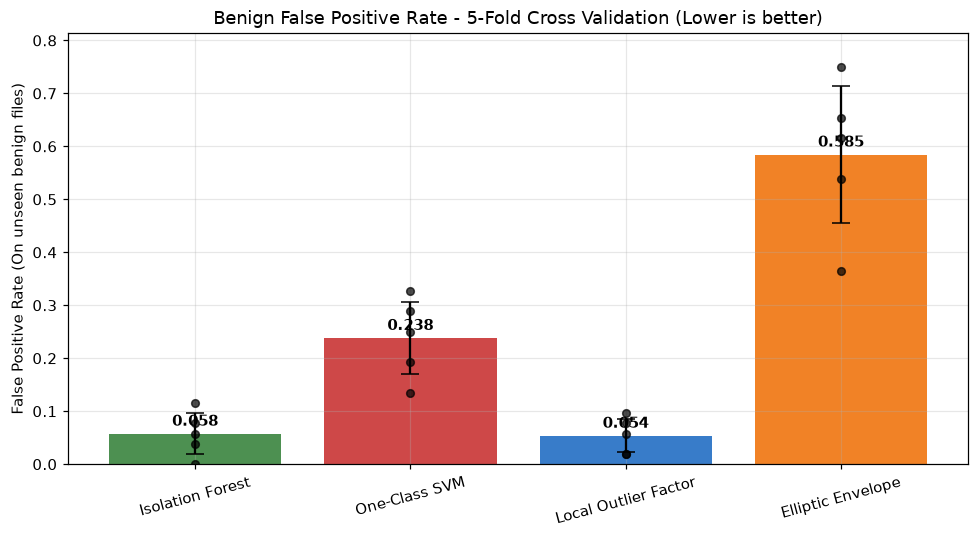

In [20]:
model_names = list(fold_results.keys())
means = [np.mean(fold_results[m]) for m in model_names]
stds = [np.std(fold_results[m]) for m in model_names]

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(
            model_names, means, yerr=stds, capsize=6,
            color = ["#2E7D32", "#C62828", "#1565C0", "#EF6C00"], 
            alpha=0.85)

# Overlay the individual fold points so the actual spread is visible not just the error bar
for i, m in enumerate(model_names):
    ax.scatter(
            [i] * len(fold_results[m]), fold_results[m],
            color = "black", zorder=3, s=25, alpha=0.7)

for bar, mean_v in zip(bars, means):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.015,
            f"{mean_v:.3f}", ha="center", fontweight="bold")

ax.set_ylabel("False Positive Rate (On unseen benign files)")
ax.set_title(f"Benign False Positive Rate - {K}-Fold Cross Validation (Lower is better)")
ax.set_ylim(0, max(means) + max(stds) + 0.1)
plt.xticks(rotation = 15)

plt.tight_layout()
plt.show()

### Anomaly Score Distributions
Every model gives each file a continuous anomaly score before deciding on a label where a lower score means the file looks more unusual. Plotting these scores shows the shape of what each model considers normal. The dashed line marks the decision threshold, and every file falling to the left of it is flagged as an anomaly. This is the most important plot for the project to see how the models treat to the benign files.

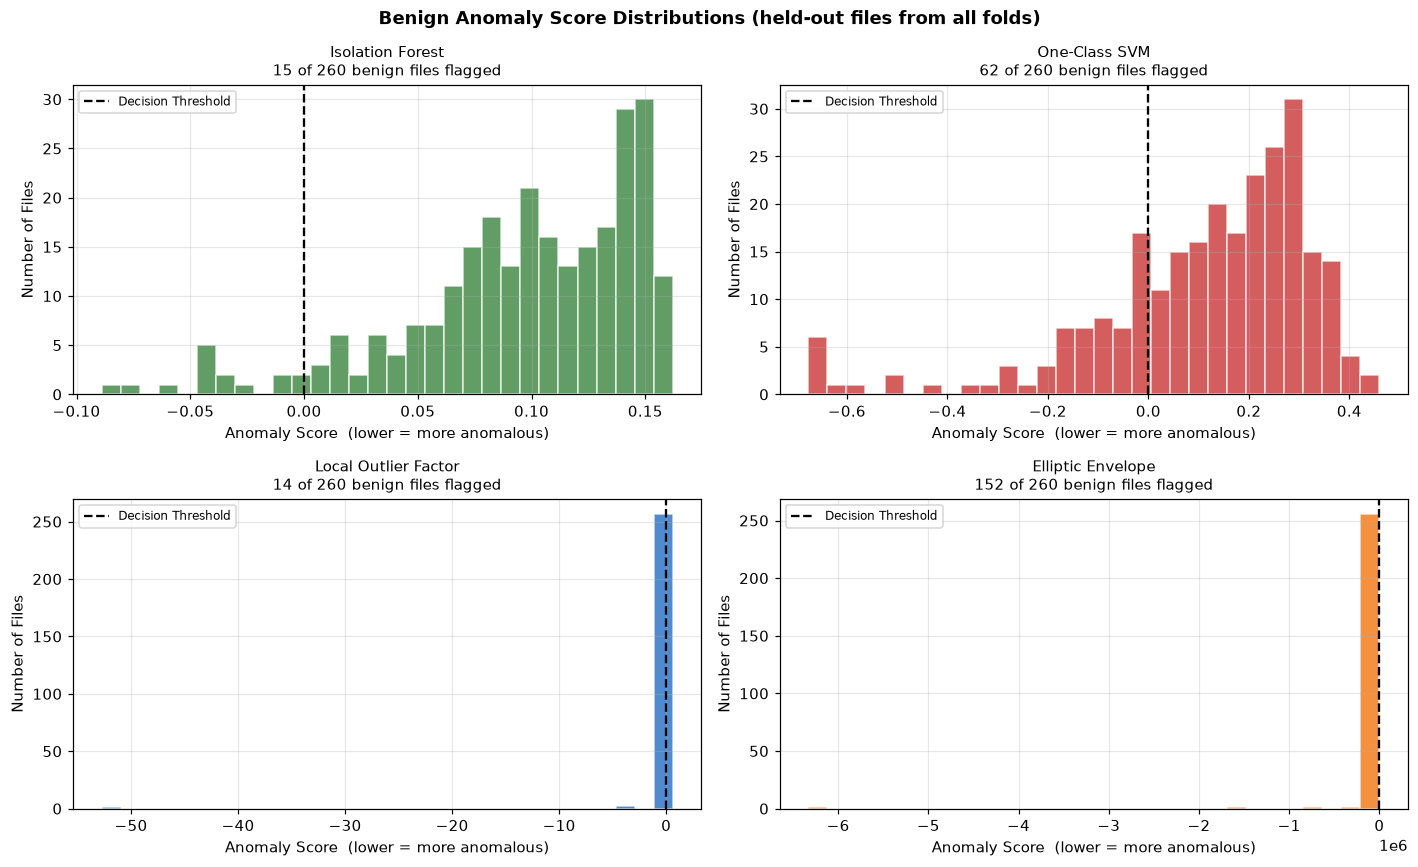

In [21]:
# Collect raw continuous scores for held out files across all folds
# decision_function: higher = more normal and lower = more anomalous Threshold is 0
holdout_scores = {name: [] for name in build_models()}

for tr_idx, te_idx in kf.split(X):
    fold_scaler = StandardScaler()
    X_tr = fold_scaler.fit_transform(X[tr_idx])
    X_te = fold_scaler.transform(X[te_idx])

    for name, model in build_models().items():
        model.fit(X_tr)
        holdout_scores[name].extend(model.decision_function(X_te))

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
colors = ["#2E7D32", "#C62828", "#1565C0", "#EF6C00"]

for ax, (name, scores), c in zip(axes.flat, holdout_scores.items(), colors):
    scores = np.array(scores)
    
    ax.hist(scores, bins=30, color=c, alpha=0.75, edgecolor="white")
    ax.axvline(0, color="black", linestyle="--", linewidth=1.5, label="Decision Threshold")
    
    n_flagged = int((scores < 0).sum())
    ax.set_title(f"{name}\n{n_flagged} of {len(scores)} benign files flagged", fontsize = 10)
    
    ax.set_xlabel("Anomaly Score  (lower = more anomalous)")
    ax.set_ylabel("Number of Files")
    ax.legend(fontsize=8)

plt.suptitle("Benign Anomaly Score Distributions (held-out files from all folds)", fontweight="bold")
plt.tight_layout()
plt.show()

### One-Class SVM Sensitivity Heatmap

The hyper parameter tuning results earlier showed that `gamma` has a far greater effect on the One-Class SVM than `nu` does. This heatmap makes that pattern easier to see. Each cell shows the mean false positive rate for one combination of the two parameters with darker cells meaning more benign files were wrongly flagged.


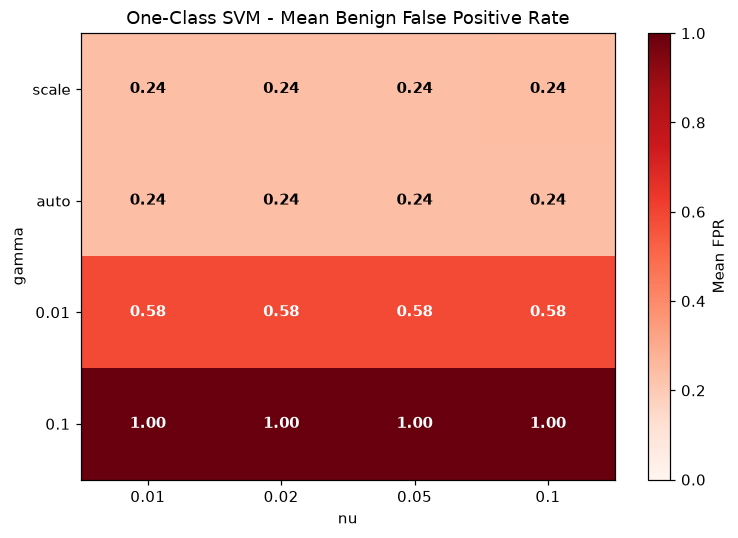

In [22]:
heat = np.zeros((len(gamma_values), len(nu_values)))

# Create mean false positive rate for each combination of nu and gamma
for gi, gamma_v in enumerate(gamma_values):
    
    for ni, nu_v in enumerate(nu_values):
        fprs = []
        
        for tr_idx, te_idx in kf.split(X):
            s = StandardScaler()
            X_tr = s.fit_transform(X[tr_idx])
            X_te = s.transform(X[te_idx])
            m = OneClassSVM(kernel="rbf", nu=nu_v, gamma=gamma_v)
            m.fit(X_tr)
            fprs.append(false_positive_rate(m.predict(X_te)))
            
        heat[gi, ni] = np.mean(fprs)

fig, ax = plt.subplots(figsize = (7, 5))
im = ax.imshow(heat, cmap="Reds", aspect="auto", vmin=0, vmax=1)

ax.set_xticks(range(len(nu_values)), [str(v) for v in nu_values])
ax.set_yticks(range(len(gamma_values)), [str(v) for v in gamma_values])
ax.set_xlabel("nu")
ax.set_ylabel("gamma")
ax.set_title("One-Class SVM - Mean Benign False Positive Rate")
ax.grid(False)

for gi in range(len(gamma_values)):
    for ni in range(len(nu_values)):
        ax.text(ni, gi, f"{heat[gi, ni]:.2f}", ha="center", va="center",
                color="white" if heat[gi, ni] > 0.5 else "black", fontweight="bold")

plt.colorbar(im, ax=ax, label="Mean FPR")
plt.tight_layout()
plt.show()

### Principal Component Analysis (PCA) - Projection of the Benign Feature Space

The feature space has 287 dimensions which cannot be viewed directly. PCA reduces it down to two dimensions so the shape of the benign data can actually be looked at. Each point is one benign file, and the colour shows the anomaly score given by the Isolation Forest, those darker red points being the ones the model considers more unusual.

The purpose here is to check whether the flagged files genuinely sit at the edge of the benign distribution or whether the model is flagging files that look perfectly ordinary. If the red points appear around the outside of the main cluster, the model is behaving sensibly. The explained variance in the axis labels also shows how much of the original information survives the reduction to two dimensions which is useful info.
- After checking the PCA plot, it is clear that the Isolation Forest is flagging files that genuinely sit at the edge of the benign distribution. The red points are mostly located around the edge of the main cluster, indicating that the model is effectively identifying anomalies based on their deviation from the normal data. This visual confirmation supports the quantitative results obtained from the false positive rates and provides confidence in the model's performance.

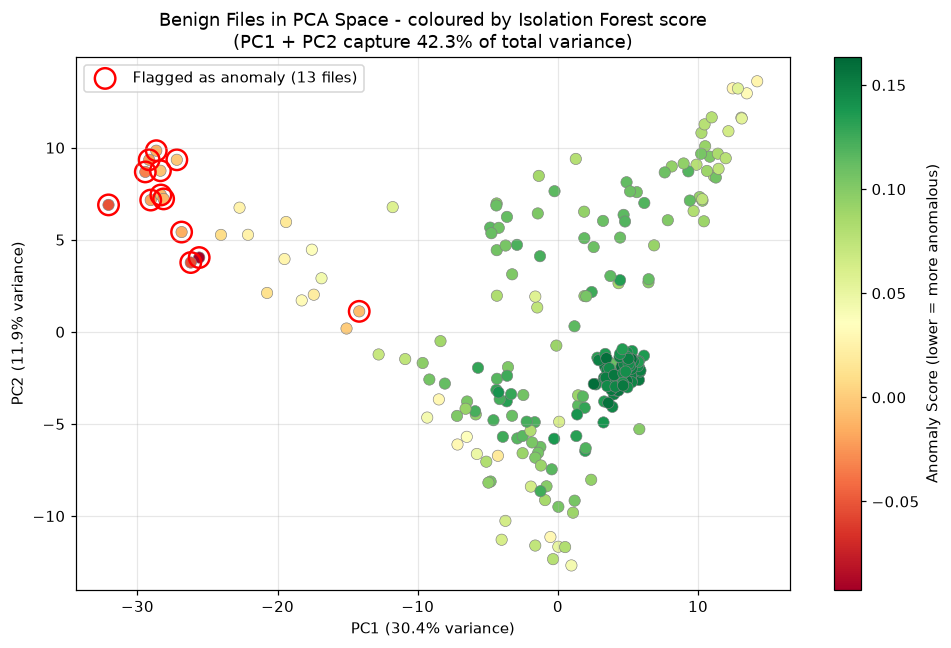

In [23]:
from sklearn.decomposition import PCA

X_std = StandardScaler().fit_transform(X) # Visualization only not used for any model
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_std)

# Score every file with a model trained on all benign data for visualization
iso_vis = IsolationForest(
    contamination = CONTAMINATION, 
    random_state = RANDOM_STATE, 
    n_estimators = 200
)

iso_vis.fit(X_std)
vis_scores = iso_vis.decision_function(X_std)
vis_flagged = iso_vis.predict(X_std) == -1

fig, ax = plt.subplots(figsize=(9, 6))
sc = ax.scatter(X_pca[:, 0], X_pca[:, 1], c=vis_scores, cmap = "RdYlGn",
                s = 55, edgecolor="grey", linewidth = 0.4)

# Ring the flagged files in red so they stand out - easy to see
ax.scatter(X_pca[vis_flagged, 0], X_pca[vis_flagged, 1],
            facecolors="none", edgecolors="red", s = 180, linewidth = 1.6,
            label=f"Flagged as anomaly ({vis_flagged.sum()} files)")

var = pca.explained_variance_ratio_
ax.set_xlabel(f"PC1 ({var[0]*100:.1f}% variance)")
ax.set_ylabel(f"PC2 ({var[1]*100:.1f}% variance)")
ax.set_title(f"Benign Files in PCA Space - coloured by Isolation Forest score\n"
                f"(PC1 + PC2 capture {var.sum()*100:.1f}% of total variance)")
ax.legend()
plt.colorbar(sc, ax=ax, label="Anomaly Score (lower = more anomalous)")
plt.tight_layout()
plt.show()

### Which Benign Files Get Flagged Most Often

The false positive rate says how many benign files were wrongly flagged but not which ones. This check counts how often each file was flagged across all folds and all four models. So any file that is repeatedly flagged by different models can be identified.

This matters because a file flagged by every model in every fold is probably a genuine outlier within the benign set rather than a mistake by one particular model. It might be an unusually small JAR or a program with a very narrow instruction mix or something else that legitimately does not look like the rest of the dataset.

In [24]:
flag_counts = {sid: 0 for sid in sample_ids}
n_evaluations = 0 # Each file is tested once per model and it appears in exactly one test fold

# Count how many times each benign file is flagged by any of the models across all folds
for tr_idx, te_idx in kf.split(X):
    fold_scaler = StandardScaler()
    X_tr = fold_scaler.fit_transform(X[tr_idx])
    X_te = fold_scaler.transform(X[te_idx])

    for name, model in build_models().items():
        model.fit(X_tr)
        preds = model.predict(X_te)
        for local_i, global_i in enumerate(te_idx):
            if preds[local_i] == -1:
                flag_counts[sample_ids[global_i]] += 1

n_models = len(build_models())

df_flags = pd.DataFrame([
    {"sample_id": sid, "times_flagged": cnt, "out_of_models": n_models}
    for sid, cnt in flag_counts.items()
])

df_flags = df_flags[df_flags["times_flagged"] > 0].sort_values(
    "times_flagged", ascending=False
).reset_index(drop=True)

print(f"Each file is tested once, by each of the {n_models} models.\n")
print(f"{len(df_flags)} of {len(sample_ids)} benign files were flagged by at least one model.\n")

consistent = df_flags[df_flags["times_flagged"] == n_models]
print(f"Flagged by ALL {n_models} models (likely genuine outliers in the benign set): {len(consistent)}")
if len(consistent):
    print(consistent[["sample_id", "times_flagged"]].to_string(index=False))

print("\nTop 40 Most Flagged benign files:\n")
print(df_flags.head(40).to_string(index=False))

Each file is tested once, by each of the 4 models.

154 of 260 benign files were flagged by at least one model.

Flagged by ALL 4 models (likely genuine outliers in the benign set): 2
              sample_id  times_flagged
      oak-upgrade-2.2.0              4
hudi-examples-k8s-1.2.0              4

Top 40 Most Flagged benign files:

                          sample_id  times_flagged  out_of_models
                  oak-upgrade-2.2.0              4              4
            hudi-examples-k8s-1.2.0              4              4
           deadbolt-core_2.10-2.4.3              3              4
                        jline-0.9.5              3              4
                      oak-run-2.2.0              3              4
 mcpdf-0.2.10-jar-with-dependencies              3              4
  tupson-jvm_3-v0.1.2-DIRTYfb94c54e              3              4
              oak-run-elastic-2.2.0              3              4
                       abbot-0.13.0              3              4
   

### Benign Files Flagged by Isolation Forest in the PCA Space

In [25]:
# List the files flagged as anomalies in the benign PCA space
anomaly_list = pd.DataFrame({
    
    "sample_id": np.array(sample_ids)[vis_flagged],
    "anomaly_score": vis_scores[vis_flagged],
    "PC1": X_pca[vis_flagged, 0],
    "PC2": X_pca[vis_flagged, 1],
    
}).sort_values("anomaly_score").reset_index(drop = True)

print(f"{vis_flagged.sum()} benign files flagged as anomalies (lower score = more anomalous)\n")
print(anomaly_list.to_string(index=False))


13 benign files flagged as anomalies (lower score = more anomalous)

                          sample_id  anomaly_score        PC1      PC2
            hudi-examples-k8s-1.2.0      -0.092343 -25.593671 4.035527
                  oak-upgrade-2.2.0      -0.053891 -26.195402 3.764164
                      oak-run-2.2.0      -0.051391 -32.063433 6.894200
  hudi-timeline-server-bundle-1.2.0      -0.033181 -29.437972 8.684518
         hudi-cli-bundle_2.13-1.2.0      -0.023153 -29.164265 9.343593
     deployment-maven-plugin-12.0.5      -0.020192 -29.052244 7.156457
              oak-run-elastic-2.2.0      -0.015032 -26.849439 5.419317
         hudi-cli-bundle_2.12-1.2.0      -0.013462 -28.655097 9.837588
       freerouting-2.2.4-executable      -0.011954 -28.132352 7.219246
               authentication-1.0.2      -0.010757 -28.327943 7.431872
            inetaddresslocator-2.18      -0.007938 -14.175575 1.113898
         closure-compiler-v20260531      -0.004846 -28.357809 8.747900
hudi-met